In [22]:
import geopandas as gpd
import matplotlib.pyplot as plt
import momepy as mp
import networkx as nx
import numpy as np
from matplotlib import colors

In [2]:
gdf_edges = gpd.read_file("../data/processed/bikenet_edges.gpkg")

In [4]:
coins = mp.COINS(gdf_edges.copy())
G_dual = mp.coins_to_nx(coins)
nx.set_node_attributes(
    G_dual,
    dict(nx.betweenness_centrality(G_dual)),
    "stroke_betweenness",
)
strokes, _ = mp.nx_to_gdf(G_dual)
strokes = strokes.explode("edge_indices").set_index("edge_indices")
gdf_cont = gdf_edges.copy()
gdf_cont["stroke_betweenness"] = strokes["stroke_betweenness"]

In [23]:
def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    new_cmap = colors.LinearSegmentedColormap.from_list(
        f"trunc({cmap.name},{minval:.2f},{maxval:.2f})",
        cmap(np.linspace(minval, maxval, n)),
    )
    return new_cmap

In [ ]:
truncate_colormap(plt.get_cmap("inferno"), 0.0, 0.7, 100)

In [ ]:
cmap = truncate_colormap(plt.get_cmap("plasma"), 0.0, 0.9, 100)

/Users/clse/Desktop/PhD/01_Code/paris_orderbike/.pixi/envs/default/lib/python3.14/site-packages/geopandas/plotting.py:746: UserWarning: Numba not installed. Using slow pure python version.
  binning = mapclassify.classify(


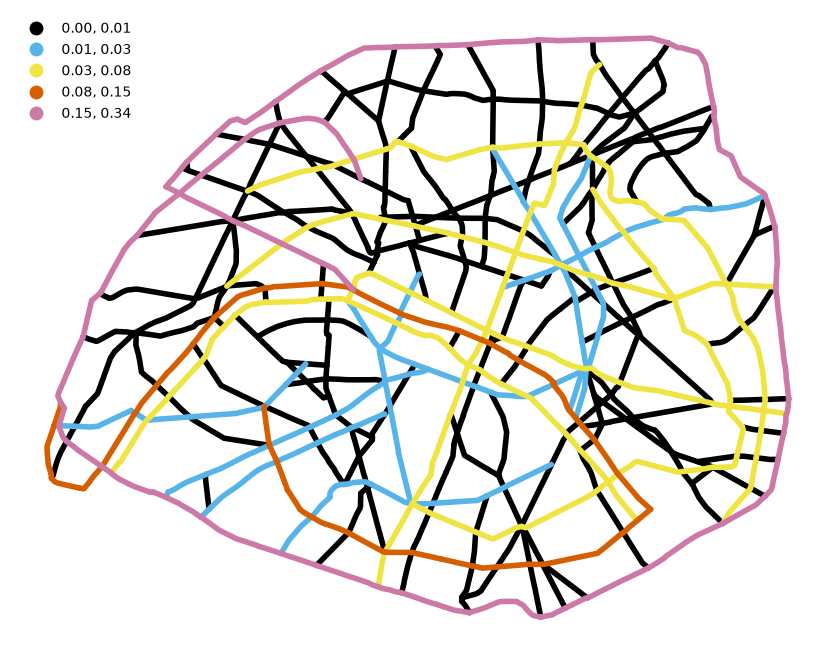

In [49]:
fig, ax = plt.subplots(figsize=([11.69, 8.27]))
gdf_cont = gdf_cont.sort_values(by="stroke_betweenness", ascending=True)
gdf_cont.plot(
    ax=ax,
    column="stroke_betweenness",
    scheme="fisherjenks",
    linewidth=4,
    capstyle="round",
    joinstyle="round",
    cmap="okabe_ito",
    legend=True,
    legend_kwds={"loc": "upper left", "frameon": False},
)
ax.axis("off")
fig.savefig("../plots/archive/db.png", dpi=500, bbox_inches="tight")